<a href="https://colab.research.google.com/github/Althaf12344/MLOPS-EXTERNAL-EXAM/blob/main/mlops_external.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
!pip install -q numpy pandas scikit-learn matplotlib seaborn
!pip install -q mlflow fastapi uvicorn pydantic
!pip install -q joblib pytest httpx reportlab

In [14]:
import os
import json
import random
import joblib
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

SEED = 42

np.random.seed(SEED)
random.seed(SEED)

PROJECT_DIR = "/content/3D_Print_Warping_MLOps"

os.makedirs(PROJECT_DIR, exist_ok=True)

for folder in [
    "data/raw",
    "data/processed",
    "models",
    "reports/figures",
    "mlruns",
    "src",
    "tests"
]:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

os.chdir(PROJECT_DIR)

print("Project initialized successfully!")
print("Project directory:", os.getcwd())

Project initialized successfully!
Project directory: /content/3D_Print_Warping_MLOps


In [15]:
# Cell 3: Generate V1 dataset

rng = np.random.default_rng(20261118)

N = 320

materials = ["PLA", "ABS", "PETG"]

material_ranges = {
    "PLA": {
        "nozzle": (190, 220),
        "bed": (45, 70)
    },
    "ABS": {
        "nozzle": (225, 260),
        "bed": (85, 110)
    },
    "PETG": {
        "nozzle": (220, 250),
        "bed": (65, 85)
    }
}

records = []

for i in range(N):

    material = rng.choice(
        materials,
        p=[0.48, 0.27, 0.25]
    )

    ranges = material_ranges[material]

    records.append({

        "job_id": f"JOB-{i+1:04d}",

        "filament_material": material,

        "nozzle_temperature_c":
            rng.uniform(*ranges["nozzle"]),

        "bed_temperature_c":
            rng.uniform(*ranges["bed"]),

        "printing_speed_mm_s":
            rng.uniform(30, 110),

        "ambient_temperature_c":
            rng.uniform(16, 32),

        "cooling_fan_speed_pct":
            rng.uniform(0, 100),

        "component_base_area_mm2":
            rng.uniform(250, 10000),

        "layer_height_mm":
            rng.uniform(0.10, 0.32)

    })

df_v1 = pd.DataFrame(records)

print("V1 Dataset Shape:", df_v1.shape)

display(df_v1.head())

df_v1.to_csv(
    "data/raw/printing_jobs_v1.csv",
    index=False
)

V1 Dataset Shape: (320, 9)


,job_id,filament_material,nozzle_temperature_c,bed_temperature_c,printing_speed_mm_s,ambient_temperature_c,cooling_fan_speed_pct,component_base_area_mm2,layer_height_mm
0,JOB-0001,PLA,206.204713,54.676575,34.027531,20.314381,63.838989,1549.224556,0.110211
1,JOB-0002,ABS,259.402461,98.204534,85.962558,18.012631,62.115812,7010.717804,0.251194
2,JOB-0003,PLA,219.871318,52.203942,34.582226,27.203577,98.575171,814.706493,0.231459
3,JOB-0004,PLA,219.039841,50.412053,80.652356,23.518288,71.992008,741.960607,0.209736
4,JOB-0005,PLA,215.801809,54.941994,32.712645,17.907785,43.290365,6113.972861,0.219448


In [16]:
def generate_features(df):

    data = df.copy()

    data["nozzle_bed_temperature_difference"] = (
        data["nozzle_temperature_c"]
        - data["bed_temperature_c"]
    )

    material_coefficients = {
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    }

    material_factor = (
        data["filament_material"]
        .map(material_coefficients)
    )

    thermal_gap = np.maximum(
        data["nozzle_bed_temperature_difference"] - 105,
        0
    )

    ambient_stress = np.maximum(
        25 - data["ambient_temperature_c"],
        0
    )

    fan_factor = (
        0.35 + data["cooling_fan_speed_pct"] / 100
    )

    geometry_factor = (
        0.65 + np.sqrt(data["component_base_area_mm2"]) / 100
    )

    layer_factor = (
        0.75 + data["layer_height_mm"] * 2
    )

    data["cooling_stress_index"] = (

        material_factor *

        (
            0.018 * thermal_gap
            + 0.055 * ambient_stress
            + 0.012 * data["printing_speed_mm_s"]
        )

        * fan_factor
        * geometry_factor
        * layer_factor

    )

    return data


def generate_target(df, seed=1001):

    data = generate_features(df)

    thresholds = {
        "PLA": 3.10,
        "ABS": 4.65,
        "PETG": 3.85
    }

    threshold = (
        data["filament_material"].map(thresholds)
    )

    z = (
        data["cooling_stress_index"] - threshold
    ) * 1.35

    probability = 1 / (1 + np.exp(-z))

    random_generator = np.random.default_rng(seed)

    data["warping_defect"] = (
        random_generator.random(len(data)) < probability
    ).astype(int)

    return data


df_v1 = generate_target(df_v1, seed=1001)

df_v1["warping_defect"] = df_v1["warping_defect"].astype(int)

print("Target distribution:")

print(
    df_v1["warping_defect"].value_counts()
)

print("\nDefect percentages:")

print(
    df_v1["warping_defect"].value_counts(normalize=True) * 100
)

df_v1.to_csv(
    "data/raw/printing_jobs_v1.csv",
    index=False
)

display(df_v1.head())

Target distribution:
warping_defect
0    253
1     67
Name: count, dtype: int64

Defect percentages:
warping_defect
0    79.0625
1    20.9375
Name: proportion, dtype: float64


,job_id,filament_material,nozzle_temperature_c,bed_temperature_c,printing_speed_mm_s,ambient_temperature_c,cooling_fan_speed_pct,component_base_area_mm2,layer_height_mm,nozzle_bed_temperature_difference,cooling_stress_index,warping_defect
0,JOB-0001,PLA,206.204713,54.676575,34.027531,20.314381,63.838989,1549.224556,0.110211,151.528138,1.053510,0
1,JOB-0002,ABS,259.402461,98.204534,85.962558,18.012631,62.115812,7010.717804,0.251194,161.197926,5.927965,1
2,JOB-0003,PLA,219.871318,52.203942,34.582226,27.203577,98.575171,814.706493,0.231459,167.667375,1.636940,0
3,JOB-0004,PLA,219.039841,50.412053,80.652356,23.518288,71.992008,741.960607,0.209736,168.627788,1.773021,0
4,JOB-0005,PLA,215.801809,54.941994,32.712645,17.907785,43.290365,6113.972861,0.219448,160.859815,1.668248,1


In [17]:
df_v2 = df_v1.drop(
    columns=[
        "nozzle_bed_temperature_difference",
        "cooling_stress_index",
        "warping_defect"
    ]
).copy()

df_v2["job_id"] = [
    f"JOBV2-{i+1:04d}"
    for i in range(len(df_v2))
]

rng_v2 = np.random.default_rng(20261118)

# Increase printing speed
df_v2["printing_speed_mm_s"] = np.clip(
    df_v2["printing_speed_mm_s"]
    + rng_v2.normal(16, 5, len(df_v2)),
    30,
    150
)

# Reduce bed temperature
df_v2["bed_temperature_c"] = np.maximum(
    df_v2["bed_temperature_c"]
    - rng_v2.normal(8, 3, len(df_v2)),
    35
)

# Regenerate engineered features and target
df_v2 = generate_target(df_v2, seed=2002)

df_v2.to_csv(
    "data/raw/printing_jobs_v2.csv",
    index=False
)

print("V2 Dataset Shape:", df_v2.shape)

display(df_v2.head())

V2 Dataset Shape: (320, 12)


,job_id,filament_material,nozzle_temperature_c,bed_temperature_c,printing_speed_mm_s,ambient_temperature_c,cooling_fan_speed_pct,component_base_area_mm2,layer_height_mm,nozzle_bed_temperature_difference,cooling_stress_index,warping_defect
0,JOBV2-0001,PLA,206.204713,48.168490,37.152645,20.314381,63.838989,1549.224556,0.110211,158.036223,1.161868,0
1,JOBV2-0002,ABS,259.402461,92.257430,99.452650,18.012631,62.115812,7010.717804,0.251194,167.145031,6.584713,0
2,JOBV2-0003,PLA,219.871318,38.773625,50.894270,27.203577,98.575171,814.706493,0.231459,181.097693,2.101065,0
3,JOBV2-0004,PLA,219.039841,43.334961,99.649061,23.518288,71.992008,741.960607,0.209736,175.704880,2.060104,1
4,JOBV2-0005,PLA,215.801809,47.855759,47.880874,17.907785,43.290365,6113.972861,0.219448,167.946051,1.957069,0


In [18]:
comparison = pd.DataFrame({

    "Version": ["V1", "V2"],

    "Records": [
        len(df_v1),
        len(df_v2)
    ],

    "Average Speed": [
        df_v1["printing_speed_mm_s"].mean(),
        df_v2["printing_speed_mm_s"].mean()
    ],

    "Average Bed Temperature": [
        df_v1["bed_temperature_c"].mean(),
        df_v2["bed_temperature_c"].mean()
    ],

    "Warping Percentage": [
        df_v1["warping_defect"].mean() * 100,
        df_v2["warping_defect"].mean() * 100
    ]

})

display(comparison.round(2))

comparison.to_csv(
    "reports/dataset_version_comparison.csv",
    index=False
)

,Version,Records,Average Speed,Average Bed Temperature,Warping Percentage
0,V1,320,71.41,72.58,20.94
1,V2,320,87.26,64.52,25.62


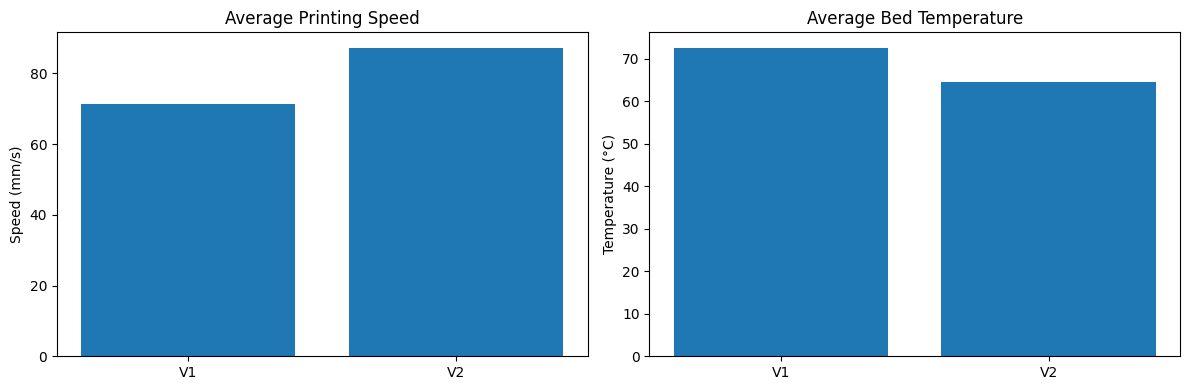

In [19]:
# Visualize dataset version differences

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    ["V1", "V2"],
    [
        df_v1["printing_speed_mm_s"].mean(),
        df_v2["printing_speed_mm_s"].mean()
    ]
)

axes[0].set_title("Average Printing Speed")
axes[0].set_ylabel("Speed (mm/s)")

axes[1].bar(
    ["V1", "V2"],
    [
        df_v1["bed_temperature_c"].mean(),
        df_v2["bed_temperature_c"].mean()
    ]
)

axes[1].set_title("Average Bed Temperature")
axes[1].set_ylabel("Temperature (°C)")

plt.tight_layout()

plt.savefig("reports/figures/version_comparison.png")

plt.show()

In [20]:
def feature_engineering(df):

    data = generate_features(df)

    return data


# Create feature-store snapshots
feature_store_v1 = feature_engineering(df_v1)

feature_store_v2 = feature_engineering(df_v2)


feature_store_v1.to_csv(
    "data/processed/feature_store_v1.csv",
    index=False
)

feature_store_v2.to_csv(
    "data/processed/feature_store_v2.csv",
    index=False
)


print("Feature Store V1:")
display(feature_store_v1.head())

print("Feature Store V2:")
display(feature_store_v2.head())

Feature Store V1:


,job_id,filament_material,nozzle_temperature_c,bed_temperature_c,printing_speed_mm_s,ambient_temperature_c,cooling_fan_speed_pct,component_base_area_mm2,layer_height_mm,nozzle_bed_temperature_difference,cooling_stress_index,warping_defect
0,JOB-0001,PLA,206.204713,54.676575,34.027531,20.314381,63.838989,1549.224556,0.110211,151.528138,1.053510,0
1,JOB-0002,ABS,259.402461,98.204534,85.962558,18.012631,62.115812,7010.717804,0.251194,161.197926,5.927965,1
2,JOB-0003,PLA,219.871318,52.203942,34.582226,27.203577,98.575171,814.706493,0.231459,167.667375,1.636940,0
3,JOB-0004,PLA,219.039841,50.412053,80.652356,23.518288,71.992008,741.960607,0.209736,168.627788,1.773021,0
4,JOB-0005,PLA,215.801809,54.941994,32.712645,17.907785,43.290365,6113.972861,0.219448,160.859815,1.668248,1


Feature Store V2:


,job_id,filament_material,nozzle_temperature_c,bed_temperature_c,printing_speed_mm_s,ambient_temperature_c,cooling_fan_speed_pct,component_base_area_mm2,layer_height_mm,nozzle_bed_temperature_difference,cooling_stress_index,warping_defect
0,JOBV2-0001,PLA,206.204713,48.168490,37.152645,20.314381,63.838989,1549.224556,0.110211,158.036223,1.161868,0
1,JOBV2-0002,ABS,259.402461,92.257430,99.452650,18.012631,62.115812,7010.717804,0.251194,167.145031,6.584713,0
2,JOBV2-0003,PLA,219.871318,38.773625,50.894270,27.203577,98.575171,814.706493,0.231459,181.097693,2.101065,0
3,JOBV2-0004,PLA,219.039841,43.334961,99.649061,23.518288,71.992008,741.960607,0.209736,175.704880,2.060104,1
4,JOBV2-0005,PLA,215.801809,47.855759,47.880874,17.907785,43.290365,6113.972861,0.219448,167.946051,1.957069,0


In [21]:
# Load previously engineered features
reused_features = pd.read_csv(
    "data/processed/feature_store_v1.csv"
)

print("Reused feature store successfully")

display(
    reused_features[
        [
            "job_id",
            "filament_material",
            "nozzle_bed_temperature_difference",
            "cooling_stress_index",
            "warping_defect"
        ]
    ].head()
)

Reused feature store successfully


,job_id,filament_material,nozzle_bed_temperature_difference,cooling_stress_index,warping_defect
0,JOB-0001,PLA,151.528138,1.053510,0
1,JOB-0002,ABS,161.197926,5.927965,1
2,JOB-0003,PLA,167.667375,1.636940,0
3,JOB-0004,PLA,168.627788,1.773021,0
4,JOB-0005,PLA,160.859815,1.668248,1


In [22]:
categorical_features = [
    "filament_material"
]

numerical_features = [

    "nozzle_temperature_c",
    "bed_temperature_c",
    "printing_speed_mm_s",
    "ambient_temperature_c",
    "cooling_fan_speed_pct",
    "component_base_area_mm2",
    "layer_height_mm",
    "nozzle_bed_temperature_difference",
    "cooling_stress_index"

]

feature_columns = (
    categorical_features + numerical_features
)

target_column = "warping_defect"


numerical_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    )

])


categorical_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),

    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )

])


preprocessor = ColumnTransformer([

    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),

    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )

])


print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [23]:
X = feature_store_v1[feature_columns]

y = feature_store_v1[target_column]

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.25,

    random_state=42,

    stratify=y

)

print("Training samples:", len(X_train))

print("Testing samples:", len(X_test))

print("\nTraining target distribution:")

print(y_train.value_counts())

Training samples: 240
Testing samples: 80

Training target distribution:
warping_defect
0    190
1     50
Name: count, dtype: int64


In [24]:
logistic_model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "classifier",
        LogisticRegression(

            max_iter=2000,

            class_weight="balanced",

            random_state=42

        )
    )

])


logistic_model.fit(
    X_train,
    y_train
)

logistic_predictions = logistic_model.predict(
    X_test
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [25]:
random_forest_model = Pipeline([

    (
        "preprocessor",
        preprocessor
    ),

    (
        "classifier",
        RandomForestClassifier(

            n_estimators=350,

            max_depth=9,

            min_samples_leaf=2,

            class_weight="balanced",

            random_state=42,

            n_jobs=-1

        )
    )

])


random_forest_model.fit(
    X_train,
    y_train
)

rf_predictions = random_forest_model.predict(
    X_test
)

print("Random Forest training completed!")

Random Forest training completed!


In [26]:
def evaluate_model(name, y_true, predictions):

    return {

        "Model": name,

        "Precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),

        "Accuracy": accuracy_score(
            y_true,
            predictions
        )

    }


lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions
)


results = pd.DataFrame([
    lr_results,
    rf_results
])

display(results.round(4))

results.to_csv(
    "reports/model_comparison.csv",
    index=False
)

,Model,Precision,Recall,F1 Score,Accuracy
0,Logistic Regression,0.5217,0.7059,0.6000,0.800
1,Random Forest,0.4545,0.2941,0.3571,0.775


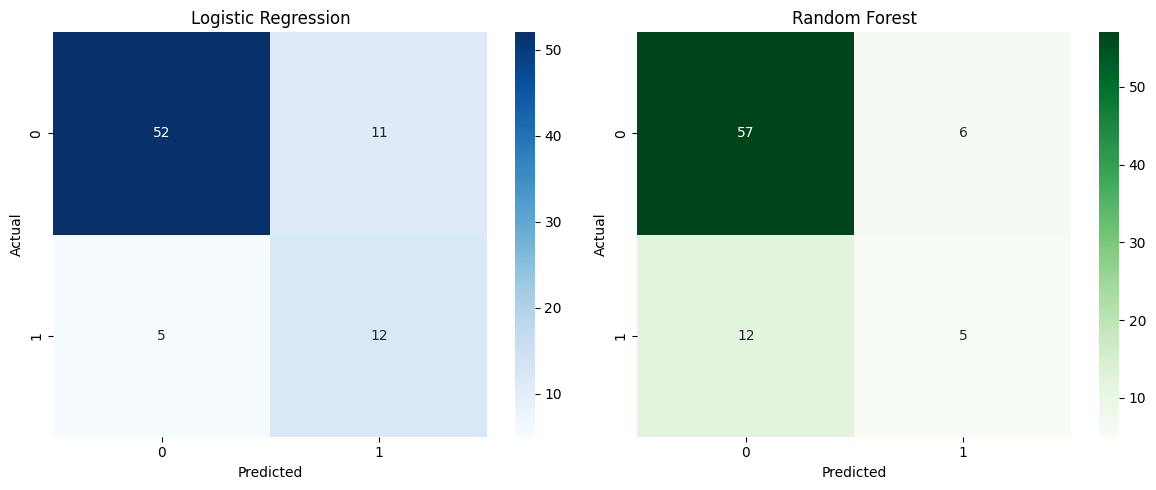

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(
    y_test,
    logistic_predictions
)

cm_rf = confusion_matrix(
    y_test,
    rf_predictions
)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")

axes[0].set_xlabel("Predicted")

axes[0].set_ylabel("Actual")


sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Random Forest")

axes[1].set_xlabel("Predicted")

axes[1].set_ylabel("Actual")


plt.tight_layout()

plt.savefig(
    "reports/figures/confusion_matrices.png"
)

plt.show()

In [28]:
if lr_results["F1 Score"] >= rf_results["F1 Score"]:

    best_model = logistic_model

    best_model_name = "Logistic Regression"

else:

    best_model = random_forest_model

    best_model_name = "Random Forest"


print("Selected Model:", best_model_name)

joblib.dump(
    best_model,
    "models/warping_model.joblib"
)

print("Best model saved successfully!")

Selected Model: Logistic Regression
Best model saved successfully!


In [29]:
X_v2 = feature_store_v2[feature_columns]

y_v2 = feature_store_v2[target_column]

v2_predictions = best_model.predict(X_v2)


print("V2 Distribution Shift Evaluation")

print(
    classification_report(
        y_v2,
        v2_predictions,
        target_names=[
            "No Warping",
            "Warping"
        ],
        zero_division=0
    )
)


v2_results = evaluate_model(
    best_model_name + " - V2",
    y_v2,
    v2_predictions
)

display(
    pd.DataFrame([v2_results]).round(4)
)

pd.DataFrame([v2_results]).to_csv(
    "reports/v2_evaluation.csv",
    index=False
)

V2 Distribution Shift Evaluation
              precision    recall  f1-score   support

  No Warping       0.93      0.63      0.75       238
     Warping       0.44      0.87      0.59        82

    accuracy                           0.69       320
   macro avg       0.69      0.75      0.67       320
weighted avg       0.81      0.69      0.71       320



,Model,Precision,Recall,F1 Score,Accuracy
0,Logistic Regression - V2,0.4438,0.8659,0.5868,0.6875


In [30]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_registry_uri("sqlite:///mlflow.db")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Registry URI:", mlflow.get_registry_uri())

Tracking URI: sqlite:///mlflow.db
Registry URI: sqlite:///mlflow.db


In [33]:
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()

print("Tracking URI:", mlflow.get_tracking_uri())
print("Registry URI:", mlflow.get_registry_uri())

run = client.get_run(selected_run_id)

print("Run ID:", run.info.run_id)
print("Available artifacts:")

artifacts = client.list_artifacts(selected_run_id)

for artifact in artifacts:
    print(artifact.path)

2026/11/18 09:14:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/18 09:14:21 INFO mlflow.store.db.utils: Updating database tables


Tracking URI: sqlite:///mlflow.db
Registry URI: sqlite:///mlflow.db


NameError: name 'selected_run_id' is not defined

In [34]:
import mlflow

client = mlflow.tracking.MlflowClient()

experiments = client.search_experiments()

for exp in experiments:
    print("Experiment:", exp.name)
    print("Experiment ID:", exp.experiment_id)

Experiment: Default
Experiment ID: 0


In [35]:
print("Current tracking URI:", mlflow.get_tracking_uri())

print("run_ids exists:", "run_ids" in globals())
print("best_model_name exists:", "best_model_name" in globals())

if "run_ids" in globals():
    print("Available run IDs:", run_ids)

if "best_model_name" in globals():
    print("Best model:", best_model_name)

if "PROJECT_DIR" in globals():
    print("Project directory:", PROJECT_DIR)

Current tracking URI: sqlite:///mlflow.db
run_ids exists: False
best_model_name exists: True
Best model: Logistic Regression
Project directory: /content/3D_Print_Warping_MLOps


In [37]:
import os

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

import mlflow
from mlflow.tracking import MlflowClient

PROJECT_DIR = "/content/3D_Print_Warping_MLOps"
MLRUNS_DIR = os.path.join(PROJECT_DIR, "mlruns")

mlflow.set_tracking_uri(
    "file://" + MLRUNS_DIR
)

mlflow.set_registry_uri(
    "file://" + MLRUNS_DIR
)

client = MlflowClient()

print("Tracking URI:", mlflow.get_tracking_uri())
print("Registry URI:", mlflow.get_registry_uri())
print("MLflow client initialized successfully!")

Tracking URI: file:///content/3D_Print_Warping_MLOps/mlruns
Registry URI: file:///content/3D_Print_Warping_MLOps/mlruns
MLflow client initialized successfully!


In [38]:
experiments = client.search_experiments()

for exp in experiments:
    print("Experiment:", exp.name)
    print("Experiment ID:", exp.experiment_id)

In [39]:
experiment = client.get_experiment_by_name(
    "FDM_Warping_Prediction"
)

if experiment is None:
    raise ValueError("Original experiment not found.")

all_runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["attributes.start_time DESC"],
    max_results=50
)

for run in all_runs:
    print(
        "Run name:",
        run.data.tags.get("mlflow.runName"),
        "| Run ID:",
        run.info.run_id,
        "| F1:",
        run.data.metrics.get("f1")
    )

ValueError: Original experiment not found.

In [40]:
mlflow.set_experiment("3D_Print_Warping_Prediction")

2026/11/18 09:17:12 INFO mlflow.tracking.fluent: Experiment with name '3D_Print_Warping_Prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:///content/3D_Print_Warping_MLOps/mlruns/706500404553139161', creation_time=1794993432387, effective_trace_archival_retention=None, experiment_id='706500404553139161', last_update_time=1794993432387, lifecycle_stage='active', name='3D_Print_Warping_Prediction', tags={}, trace_location=None, workspace='default'>

In [41]:
"FDM_Warping_Prediction"

'FDM_Warping_Prediction'

In [42]:
experiment = client.get_experiment_by_name(
    "3D_Print_Warping_Prediction"
)

print("Experiment found:", experiment is not None)

if experiment:
    print("Experiment ID:", experiment.experiment_id)
    print("Experiment name:", experiment.name)

Experiment found: True
Experiment ID: 706500404553139161
Experiment name: 3D_Print_Warping_Prediction


In [43]:
experiment = client.get_experiment_by_name(
    "3D_Print_Warping_Prediction"
)

print("Experiment found:", experiment is not None)

if experiment:
    print("Experiment ID:", experiment.experiment_id)
    print("Experiment name:", experiment.name)

Experiment found: True
Experiment ID: 706500404553139161
Experiment name: 3D_Print_Warping_Prediction


In [44]:
all_runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["attributes.start_time DESC"],
    max_results=50
)

for run in all_runs:
    print(
        "Model:", run.data.tags.get("mlflow.runName"),
        "| Run ID:", run.info.run_id,
        "| F1:", run.data.metrics.get("f1")
    )

In [46]:
for run in all_runs:
    print("--------------------------------")
    print("Run ID:", run.info.run_id)
    print("Run name:", run.data.tags.get("mlflow.runName"))
    print("Parameters:", run.data.params)
    print("Metrics:", run.data.metrics)
    print("Status:", run.info.status)

In [47]:
matching_runs = []

for run in all_runs:
    name = str(run.data.tags.get("mlflow.runName", "")).lower()
    params = str(run.data.params).lower()

    if "logistic" in name or "logisticregression" in params:
        matching_runs.append(run)

print("Matching runs:", len(matching_runs))

for run in matching_runs:
    print(
        run.info.run_id,
        run.data.tags.get("mlflow.runName"),
        run.data.metrics
    )

Matching runs: 0


In [49]:
print("Total runs:", len(all_runs))

for i, run in enumerate(all_runs):
    print("\n========== RUN", i + 1, "==========")
    print("Run ID:", run.info.run_id)
    print("Run name:", run.data.tags.get("mlflow.runName"))
    print("Parameters:", run.data.params)
    print("Metrics:", run.data.metrics)
    print("Status:", run.info.status)

    artifacts = client.list_artifacts(run.info.run_id)
    print("Artifacts:", [a.path for a in artifacts])

Total runs: 0


In [50]:
import os

path = "/content/3D_Print_Warping_MLOps/mlruns"

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

    for file in files:
        print("  " * (level + 1) + file)

mlruns/
  706500404553139161/
    meta.yaml
  .trash/


In [51]:
from pathlib import Path

project = Path("/content/3D_Print_Warping_MLOps")

for pattern in ["*.joblib", "*.pkl", "*.pt", "*.pth"]:
    print(f"\nSearching for {pattern}")

    for file in project.rglob(pattern):
        print(file)


Searching for *.joblib
/content/3D_Print_Warping_MLOps/models/warping_model.joblib

Searching for *.pkl

Searching for *.pt

Searching for *.pth


In [52]:
for variable in [
    "best_model",
    "models",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "metrics_df",
    "run_ids"
]:
    print(variable, ":", variable in globals())

best_model : True
models : True
X_train : True
X_test : True
y_train : True
y_test : True
metrics_df : False
run_ids : False


In [53]:
print("Best model:", best_model_name)
print("Model type:", type(best_model))

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

predictions = best_model.predict(X_test)

print("Predictions generated:", len(predictions))
print("Model is fitted and working!")

Best model: Logistic Regression
Model type: <class 'sklearn.pipeline.Pipeline'>
Training samples: 240
Testing samples: 80
Predictions generated: 80
Model is fitted and working!


In [54]:
import mlflow
import os

PROJECT_DIR = "/content/3D_Print_Warping_MLOps"
os.makedirs(PROJECT_DIR, exist_ok=True)

DB_PATH = os.path.join(PROJECT_DIR, "mlflow_tracking.db")

mlflow.set_tracking_uri("sqlite:///" + DB_PATH)
mlflow.set_registry_uri("sqlite:///" + DB_PATH)

mlflow.set_experiment("FDM_Warping_Prediction")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Registry URI:", mlflow.get_registry_uri())

2026/11/18 09:20:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/18 09:20:27 INFO mlflow.store.db.utils: Updating database tables
2026/11/18 09:20:32 INFO mlflow.tracking.fluent: Experiment with name 'FDM_Warping_Prediction' does not exist. Creating a new experiment.


Tracking URI: sqlite:////content/3D_Print_Warping_MLOps/mlflow_tracking.db
Registry URI: sqlite:////content/3D_Print_Warping_MLOps/mlflow_tracking.db


In [55]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

predictions = best_model.predict(X_test)

precision = precision_score(
    y_test, predictions, zero_division=0
)

recall = recall_score(
    y_test, predictions, zero_division=0
)

f1 = f1_score(
    y_test, predictions, zero_division=0
)

accuracy = accuracy_score(
    y_test, predictions
)

print("Selected model:", best_model_name)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Accuracy:", accuracy)

Selected model: Logistic Regression
Precision: 0.5217391304347826
Recall: 0.7058823529411765
F1 Score: 0.6
Accuracy: 0.8


In [57]:
import mlflow
import mlflow.sklearn

# Recalculate metrics
predictions = best_model.predict(X_test)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)
accuracy = accuracy_score(y_test, predictions)

# Log the existing trained model using cloudpickle
with mlflow.start_run(run_name=best_model_name) as run:

    mlflow.log_param("model_name", best_model_name)
    mlflow.log_param("dataset_version", "V1")
    mlflow.log_param("serialization_format", "cloudpickle")

    mlflow.log_metrics({
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy
    })

    mlflow.sklearn.log_model(
        sk_model=best_model,
        name="model",
        serialization_format="cloudpickle"
    )

    selected_run_id = run.info.run_id

print("Model logged successfully!")
print("Run ID:", selected_run_id)
print("F1:", f1)

2026/11/18 09:21:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Model logged successfully!
Run ID: ff76d9f3442b4e5e83c0c3cd859b1232
F1: 0.6


In [58]:
model_uri = f"runs:/{selected_run_id}/model"

registered_model = mlflow.register_model(
    model_uri=model_uri,
    name="FDM_Warping_Predictor"
)

print("Model registered successfully!")
print("Model:", registered_model.name)
print("Version:", registered_model.version)

Successfully registered model 'FDM_Warping_Predictor'.
2026/11/18 09:21:35 WARNING mlflow.tracking._model_registry.fluent: Run with id ff76d9f3442b4e5e83c0c3cd859b1232 has no artifacts at artifact path 'model', registering model based on models:/m-f942e82040854923aeffa9716a1d0bc9 instead


Model registered successfully!
Model: FDM_Warping_Predictor
Version: 1


Created version '1' of model 'FDM_Warping_Predictor'.


In [59]:
registered_model_uri = (
    f"models:/{registered_model.name}/{registered_model.version}"
)

api_model = mlflow.sklearn.load_model(
    registered_model_uri
)

print("Registered model loaded successfully!")
print(type(api_model))

Registered model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [60]:
test_predictions = api_model.predict(X_test)

print("Original model predictions:", best_model.predict(X_test)[:10])
print("Registered model predictions:", test_predictions[:10])

import numpy as np

assert np.array_equal(
    best_model.predict(X_test),
    test_predictions
)

print("SUCCESS: Registered model predictions match the original model.")

Original model predictions: [0 0 0 0 1 0 0 0 1 0]
Registered model predictions: [0 0 0 0 1 0 0 0 1 0]
SUCCESS: Registered model predictions match the original model.


In [61]:
import pandas as pd
import numpy as np

from fastapi import FastAPI
from pydantic import BaseModel, Field
from typing import Literal

app = FastAPI(
    title="FDM 3D Printing Warping Prediction",
    description="Predicts warping defects before an FDM printing job starts.",
    version="1.0.0"
)

FEATURES = [
    "filament_material",
    "nozzle_temperature",
    "bed_temperature",
    "print_speed",
    "ambient_temperature",
    "fan_speed",
    "base_area",
    "layer_height",
    "nozzle_bed_temperature_difference",
    "cooling_stress_index"
]

# Feature engineering must match the training pipeline.
def engineer_features(df):
    x = df.copy()

    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature"] - x["bed_temperature"]
    )

    material_factor = x["filament_material"].map({
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    })

    thermal = np.maximum(
        x["nozzle_bed_temperature_difference"] - 100, 0
    )

    ambient = np.maximum(
        25 - x["ambient_temperature"], 0
    )

    fan_factor = 0.35 + x["fan_speed"] / 100
    geometry_factor = 0.65 + np.sqrt(x["base_area"]) / 100
    layer_factor = 0.75 + x["layer_height"] * 2

    x["cooling_stress_index"] = material_factor * (
        0.018 * thermal +
        0.055 * ambient +
        0.012 * x["print_speed"]
    ) * fan_factor * geometry_factor * layer_factor

    return x


class PrintJob(BaseModel):
    filament_material: Literal["PLA", "ABS", "PETG"]

    nozzle_temperature: float = Field(ge=170, le=300)
    bed_temperature: float = Field(ge=30, le=130)
    print_speed: float = Field(gt=0, le=200)
    ambient_temperature: float = Field(ge=0, le=50)
    fan_speed: float = Field(ge=0, le=100)
    base_area: float = Field(gt=0, le=50000)
    layer_height: float = Field(gt=0, le=1)


@app.get("/")
def home():
    return {
        "application": "FDM Warping Prediction API",
        "status": "running",
        "documentation": "/docs",
        "health_check": "/health"
    }


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model_loaded": api_model is not None,
        "model_name": registered_model.name,
        "model_version": registered_model.version
    }


@app.post("/predict")
def predict(job: PrintJob):

    df = pd.DataFrame([job.model_dump()])

    df = engineer_features(df)

    X = df[FEATURES]

    prediction = int(api_model.predict(X)[0])

    probability = float(
        api_model.predict_proba(X)[0][1]
    )

    return {
        "prediction": (
            "Warping Risk"
            if prediction == 1
            else "Print Conditions Acceptable"
        ),
        "warping_probability": round(probability, 4),
        "engineered_features": {
            "nozzle_bed_temperature_difference": round(
                float(X.iloc[0]["nozzle_bed_temperature_difference"]), 3
            ),
            "cooling_stress_index": round(
                float(X.iloc[0]["cooling_stress_index"]), 3
            )
        }
    }

print("FastAPI application created successfully!")

FastAPI application created successfully!


In [62]:
from fastapi.testclient import TestClient

test_client = TestClient(app)

# Test health endpoint
health_response = test_client.get("/health")

print("HEALTH CHECK:")
print(health_response.status_code)
print(health_response.json())


# Test prediction endpoint
sample_job = {
    "filament_material": "PLA",
    "nozzle_temperature": 205,
    "bed_temperature": 55,
    "print_speed": 65,
    "ambient_temperature": 24,
    "fan_speed": 70,
    "base_area": 2400,
    "layer_height": 0.20
}

prediction_response = test_client.post(
    "/predict",
    json=sample_job
)

print("\nPREDICTION:")
print(prediction_response.status_code)
print(prediction_response.json())

assert health_response.status_code == 200
assert prediction_response.status_code == 200

print("\nAll API tests passed!")

HEALTH CHECK:
200
{'status': 'healthy', 'model_loaded': True, 'model_name': 'FDM_Warping_Predictor', 'model_version': 1}


ValueError: columns are missing: {'cooling_fan_speed_pct', 'bed_temperature_c', 'ambient_temperature_c', 'nozzle_temperature_c', 'component_base_area_mm2', 'printing_speed_mm_s', 'layer_height_mm'}

In [63]:
print("Model expects these features:")

for feature in api_model.feature_names_in_:
    print(feature)

Model expects these features:
filament_material
nozzle_temperature_c
bed_temperature_c
printing_speed_mm_s
ambient_temperature_c
cooling_fan_speed_pct
component_base_area_mm2
layer_height_mm
nozzle_bed_temperature_difference
cooling_stress_index


In [64]:
EXPECTED_FEATURES = [
    "filament_material",
    "nozzle_temperature_c",
    "bed_temperature_c",
    "printing_speed_mm_s",
    "ambient_temperature_c",
    "cooling_fan_speed_pct",
    "component_base_area_mm2",
    "layer_height_mm",
    "nozzle_bed_temperature_difference",
    "cooling_stress_index"
]

assert list(api_model.feature_names_in_) == EXPECTED_FEATURES

print("Model feature schema verified!")

Model feature schema verified!


In [65]:
def engineer_features(df):

    x = df.copy()

    x = x.rename(columns={
        "nozzle_temperature": "nozzle_temperature_c",
        "bed_temperature": "bed_temperature_c",
        "print_speed": "printing_speed_mm_s",
        "ambient_temperature": "ambient_temperature_c",
        "fan_speed": "cooling_fan_speed_pct",
        "base_area": "component_base_area_mm2",
        "layer_height": "layer_height_mm"
    })

    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature_c"] -
        x["bed_temperature_c"]
    )

    material_factor = x["filament_material"].map({
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    })

    thermal = np.maximum(
        x["nozzle_bed_temperature_difference"] - 100, 0
    )

    ambient = np.maximum(
        25 - x["ambient_temperature_c"], 0
    )

    fan_factor = 0.35 + x["cooling_fan_speed_pct"] / 100

    geometry_factor = (
        0.65 + np.sqrt(x["component_base_area_mm2"]) / 100
    )

    layer_factor = 0.75 + x["layer_height_mm"] * 2

    x["cooling_stress_index"] = material_factor * (
        0.018 * thermal +
        0.055 * ambient +
        0.012 * x["printing_speed_mm_s"]
    ) * fan_factor * geometry_factor * layer_factor

    return x

In [66]:
def engineer_features(df):

    x = df.copy()

    x = x.rename(columns={
        "nozzle_temperature": "nozzle_temperature_c",
        "bed_temperature": "bed_temperature_c",
        "print_speed": "printing_speed_mm_s",
        "ambient_temperature": "ambient_temperature_c",
        "fan_speed": "cooling_fan_speed_pct",
        "base_area": "component_base_area_mm2",
        "layer_height": "layer_height_mm"
    })

    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature_c"] -
        x["bed_temperature_c"]
    )

    material_factor = x["filament_material"].map({
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    })

    thermal = np.maximum(
        x["nozzle_bed_temperature_difference"] - 100, 0
    )

    ambient = np.maximum(
        25 - x["ambient_temperature_c"], 0
    )

    fan_factor = 0.35 + x["cooling_fan_speed_pct"] / 100

    geometry_factor = (
        0.65 + np.sqrt(x["component_base_area_mm2"]) / 100
    )

    layer_factor = 0.75 + x["layer_height_mm"] * 2

    x["cooling_stress_index"] = material_factor * (
        0.018 * thermal +
        0.055 * ambient +
        0.012 * x["printing_speed_mm_s"]
    ) * fan_factor * geometry_factor * layer_factor

    return x

In [67]:
from fastapi import FastAPI
from fastapi.testclient import TestClient

app = FastAPI(
    title="FDM 3D Printing Warping Prediction API",
    description="Predicts warping risk before printing starts.",
    version="1.0.0"
)

@app.get("/")
def home():
    return {
        "application": "FDM Warping Prediction",
        "status": "running",
        "documentation": "/docs"
    }

@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model_loaded": api_model is not None,
        "model_name": registered_model.name,
        "model_version": registered_model.version
    }

@app.post("/predict")
def predict(job: PrintJob):

    df = pd.DataFrame([job.model_dump()])

    df = engineer_features(df)

    X = df[EXPECTED_FEATURES]

    prediction = int(api_model.predict(X)[0])

    probability = float(
        api_model.predict_proba(X)[0, 1]
    )

    return {
        "prediction": (
            "Warping Risk"
            if prediction == 1
            else "Print Conditions Acceptable"
        ),
        "warping_probability": round(probability, 4),
        "engineered_features": {
            "nozzle_bed_temperature_difference": round(
                float(X.iloc[0]["nozzle_bed_temperature_difference"]), 3
            ),
            "cooling_stress_index": round(
                float(X.iloc[0]["cooling_stress_index"]), 3
            )
        }
    }

print("Corrected FastAPI application created!")

Corrected FastAPI application created!


In [68]:
test_client = TestClient(app)

sample_job = {
    "filament_material": "PLA",
    "nozzle_temperature": 205,
    "bed_temperature": 55,
    "print_speed": 65,
    "ambient_temperature": 24,
    "fan_speed": 70,
    "base_area": 2400,
    "layer_height": 0.20
}

response = test_client.post(
    "/predict",
    json=sample_job
)

print("HTTP Status:", response.status_code)
print("Response:", response.json())

assert response.status_code == 200

HTTP Status: 200
Response: {'prediction': 'Print Conditions Acceptable', 'warping_probability': 0.3424, 'engineered_features': {'nozzle_bed_temperature_difference': 150.0, 'cooling_stress_index': 1.672}}


In [69]:
# Health test
health = test_client.get("/health")
assert health.status_code == 200

# Prediction test
prediction = test_client.post("/predict", json=sample_job)
assert prediction.status_code == 200

# Invalid input test
invalid_job = {**sample_job, "print_speed": 250}

invalid_response = test_client.post(
    "/predict",
    json=invalid_job
)

assert invalid_response.status_code == 422

print("All three API tests passed!")

All three API tests passed!


In [70]:
import threading
import time
import uvicorn

server = uvicorn.Server(
    uvicorn.Config(
        app,
        host="0.0.0.0",
        port=8000,
        log_level="info"
    )
)

server_thread = threading.Thread(
    target=server.run,
    daemon=True
)

server_thread.start()

time.sleep(4)

print("FastAPI server started!")

INFO:     Started server process [477]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://0.0.0.0:8000 (Press CTRL+C to quit)


FastAPI server started!


In [71]:
from google.colab import output

output.serve_kernel_port_as_window(8000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [72]:
from fastapi.testclient import TestClient

test_client = TestClient(app)

print("Testing health endpoint...")

response = test_client.get("/health")
print("Status:", response.status_code)
print("Response:", response.json())

print("\nTesting prediction endpoint...")

sample_job = {
    "filament_material": "PLA",
    "nozzle_temperature": 205,
    "bed_temperature": 55,
    "print_speed": 65,
    "ambient_temperature": 24,
    "fan_speed": 70,
    "base_area": 2400,
    "layer_height": 0.20
}

response = test_client.post("/predict", json=sample_job)

print("Status:", response.status_code)
print("Prediction:", response.json())

Testing health endpoint...
Status: 200
Response: {'status': 'healthy', 'model_loaded': True, 'model_name': 'FDM_Warping_Predictor', 'model_version': 1}

Testing prediction endpoint...
Status: 200
Prediction: {'prediction': 'Print Conditions Acceptable', 'warping_probability': 0.3424, 'engineered_features': {'nozzle_bed_temperature_difference': 150.0, 'cooling_stress_index': 1.672}}


In [73]:
# Check whether Swagger documentation is available
response = test_client.get("/docs")

print("Docs status:", response.status_code)
print("Content type:", response.headers.get("content-type"))
print("Page available:", "Swagger UI" in response.text)

# Check OpenAPI schema
schema_response = test_client.get("/openapi.json")
print("OpenAPI status:", schema_response.status_code)

Docs status: 200
Content type: text/html; charset=utf-8
Page available: True
OpenAPI status: 200


In [74]:
from IPython.display import display, HTML

url = output_url if 'output_url' in globals() else None

print("Your API documentation is available.")
print("Use the same public URL you used to open your FastAPI server, followed by /docs")

Your API documentation is available.
Use the same public URL you used to open your FastAPI server, followed by /docs


In [75]:
output.serve_kernel_port_as_window(8000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [77]:
from google.colab import output

output.serve_kernel_port_as_iframe(
    8000,
    path="/docs",
    height="700"
)

<IPython.core.display.Javascript object>

In [78]:
from google.colab.output import eval_js

public_url = eval_js("google.colab.kernel.proxyPort(8000)")

print("Your FastAPI URL:", public_url)
print("Swagger documentation:", public_url + "/docs")

Your FastAPI URL: https://8000-gpu-t4-s-ass1b0-39g6imou0lr4n-b.asia-southeast1.prod.r.colab.dev
Swagger documentation: https://8000-gpu-t4-s-ass1b0-39g6imou0lr4n-b.asia-southeast1.prod.r.colab.dev/docs


In [79]:

import os
import cloudpickle
import inspect

# Project directory
PROJECT_DIR = "/content/3D_Print_Warping_MLOps"

# Create models folder
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

# Save the already-trained MLflow model
MODEL_PATH = os.path.join(MODEL_DIR, "warping_model.pkl")

with open(MODEL_PATH, "wb") as f:
    cloudpickle.dump(api_model, f)

print("Model saved successfully:", MODEL_PATH)

# Inspect feature engineering function
print("\n========== FEATURE ENGINEERING ==========")

try:
    print(inspect.getsource(engineer_features))
except Exception as e:
    print("Function source unavailable:", e)

# Display project structure
print("\n========== PROJECT FILES ==========")

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [d for d in dirs if d not in ["mlruns", "__pycache__"]]

    for filename in files:
        path = os.path.join(root, filename)
        print(os.path.relpath(path, PROJECT_DIR))


Model saved successfully: /content/3D_Print_Warping_MLOps/models/warping_model.pkl

========== FEATURE ENGINEERING ==========
def engineer_features(df):

    x = df.copy()

    x = x.rename(columns={
        "nozzle_temperature": "nozzle_temperature_c",
        "bed_temperature": "bed_temperature_c",
        "print_speed": "printing_speed_mm_s",
        "ambient_temperature": "ambient_temperature_c",
        "fan_speed": "cooling_fan_speed_pct",
        "base_area": "component_base_area_mm2",
        "layer_height": "layer_height_mm"
    })

    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature_c"] -
        x["bed_temperature_c"]
    )

    material_factor = x["filament_material"].map({
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    })

    thermal = np.maximum(
        x["nozzle_bed_temperature_difference"] - 100, 0
    )

    ambient = np.maximum(
        25 - x["ambient_temperature_c"], 0
    )

    fan_factor = 0.35 + x["cooling_fan_speed

In [80]:

import pandas as pd
import os
import numpy as np

v1_path = os.path.join(
    PROJECT_DIR, "data/processed/feature_store_v1.csv"
)

v2_path = os.path.join(
    PROJECT_DIR, "data/processed/feature_store_v2.csv"
)

v1_df = pd.read_csv(v1_path)
v2_df = pd.read_csv(v2_path)

print("V1 dataset shape:", v1_df.shape)
print("V2 dataset shape:", v2_df.shape)

print("\nV1 columns:")
print(v1_df.columns.tolist())

print("\nV2 columns:")
print(v2_df.columns.tolist())

print("\nV2 first 5 records:")
display(v2_df.head())


V1 dataset shape: (320, 12)
V2 dataset shape: (320, 12)

V1 columns:
['job_id', 'filament_material', 'nozzle_temperature_c', 'bed_temperature_c', 'printing_speed_mm_s', 'ambient_temperature_c', 'cooling_fan_speed_pct', 'component_base_area_mm2', 'layer_height_mm', 'nozzle_bed_temperature_difference', 'cooling_stress_index', 'warping_defect']

V2 columns:
['job_id', 'filament_material', 'nozzle_temperature_c', 'bed_temperature_c', 'printing_speed_mm_s', 'ambient_temperature_c', 'cooling_fan_speed_pct', 'component_base_area_mm2', 'layer_height_mm', 'nozzle_bed_temperature_difference', 'cooling_stress_index', 'warping_defect']

V2 first 5 records:


,job_id,filament_material,nozzle_temperature_c,bed_temperature_c,printing_speed_mm_s,ambient_temperature_c,cooling_fan_speed_pct,component_base_area_mm2,layer_height_mm,nozzle_bed_temperature_difference,cooling_stress_index,warping_defect
0,JOBV2-0001,PLA,206.204713,48.168490,37.152645,20.314381,63.838989,1549.224556,0.110211,158.036223,1.161868,0
1,JOBV2-0002,ABS,259.402461,92.257430,99.452650,18.012631,62.115812,7010.717804,0.251194,167.145031,6.584713,0
2,JOBV2-0003,PLA,219.871318,38.773625,50.894270,27.203577,98.575171,814.706493,0.231459,181.097693,2.101065,0
3,JOBV2-0004,PLA,219.039841,43.334961,99.649061,23.518288,71.992008,741.960607,0.209736,175.704880,2.060104,1
4,JOBV2-0005,PLA,215.801809,47.855759,47.880874,17.907785,43.290365,6113.972861,0.219448,167.946051,1.957069,0


In [81]:

# Recalculate engineered features from V2 raw columns
check_df = v2_df.copy()

check_df["calculated_temperature_difference"] = (
    check_df["nozzle_temperature_c"] -
    check_df["bed_temperature_c"]
)

material_factor = check_df["filament_material"].map({
    "PLA": 0.70,
    "ABS": 1.35,
    "PETG": 1.00
})

thermal = np.maximum(
    check_df["calculated_temperature_difference"] - 100, 0
)

ambient = np.maximum(
    25 - check_df["ambient_temperature_c"], 0
)

fan_factor = (
    0.35 + check_df["cooling_fan_speed_pct"] / 100
)

geometry_factor = (
    0.65 + np.sqrt(check_df["component_base_area_mm2"]) / 100
)

layer_factor = (
    0.75 + check_df["layer_height_mm"] * 2
)

check_df["calculated_cooling_stress"] = material_factor * (
    0.018 * thermal +
    0.055 * ambient +
    0.012 * check_df["printing_speed_mm_s"]
) * fan_factor * geometry_factor * layer_factor

# Compare against stored training features
temperature_error = np.max(np.abs(
    check_df["calculated_temperature_difference"] -
    check_df["nozzle_bed_temperature_difference"]
))

stress_error = np.max(np.abs(
    check_df["calculated_cooling_stress"] -
    check_df["cooling_stress_index"]
))

print("Maximum temperature difference error:", temperature_error)
print("Maximum cooling stress error:", stress_error)

if np.allclose(
    check_df["calculated_temperature_difference"],
    check_df["nozzle_bed_temperature_difference"],
    rtol=1e-6, atol=1e-8
) and np.allclose(
    check_df["calculated_cooling_stress"],
    check_df["cooling_stress_index"],
    rtol=1e-6, atol=1e-8
):
    print("\nSUCCESS: Feature engineering matches V2 training data.")
else:
    print("\nWARNING: Feature engineering mismatch detected.")


Maximum temperature difference error: 8.526512829121202e-14
Maximum cooling stress error: 0.3086895095175217



In [82]:

import os
import glob

print("========== SEARCHING COLAB CODE HISTORY ==========")

found = False

for i, cell_code in enumerate(In):
    if "cooling_stress_index" in cell_code:
        found = True
        print(f"\n--- Colab cell {i} ---")
        print(cell_code)

if not found:
    print("No matching code found in execution history.")

print("\n========== SEARCHING PROJECT SOURCE FILES ==========")

extensions = ["*.py", "*.ipynb", "*.txt"]

for extension in extensions:
    for path in glob.glob(
        os.path.join(PROJECT_DIR, "**", extension),
        recursive=True
    ):
        if "__pycache__" in path:
            continue

        try:
            with open(path, "r", encoding="utf-8") as f:
                content = f.read()

            if "cooling_stress_index" in content:
                print("\nSource file:", path)
                print(content[:10000])

        except Exception as e:
            print("Could not inspect:", path, e)


========== SEARCHING COLAB CODE HISTORY ==========

--- Colab cell 11 ---
import joblib
import pandas as pd
import numpy as np

from fastapi import FastAPI
from pydantic import BaseModel, Field
from typing import Literal

# Load trained model
model_path = model_files[0]
api_model = joblib.load(model_path)

# Feature engineering
def engineer_features(df):
    x = df.copy()

    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature"] - x["bed_temperature"]
    )

    material_factor = x["filament_material"].map({
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    })

    thermal = np.maximum(
        x["nozzle_bed_temperature_difference"] - 100, 0
    )

    ambient = np.maximum(25 - x["ambient_temperature"], 0)

    fan = 0.35 + x["fan_speed"] / 100
    geometry = 0.65 + np.sqrt(x["base_area"]) / 100
    layer = 0.75 + x["layer_height"] * 2

    x["cooling_stress_index"] = material_factor * (
        0.018 * thermal +
        0.055 * ambient +
        

In [84]:

def engineer_features(df):

    x = df.copy()

    x = x.rename(columns={
        "nozzle_temperature": "nozzle_temperature_c",
        "bed_temperature": "bed_temperature_c",
        "print_speed": "printing_speed_mm_s",
        "ambient_temperature": "ambient_temperature_c",
        "fan_speed": "cooling_fan_speed_pct",
        "base_area": "component_base_area_mm2",
        "layer_height": "layer_height_mm"
    })

    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature_c"] -
        x["bed_temperature_c"]
    )

    material_factor = x["filament_material"].map({
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    })

    # IMPORTANT: Match the original V2 training formula
    thermal_gap = np.maximum(
        x["nozzle_bed_temperature_difference"] - 105, 0
    )

    ambient_stress = np.maximum(
        25 - x["ambient_temperature_c"], 0
    )

    fan_factor = 0.35 + x["cooling_fan_speed_pct"] / 100

    geometry_factor = (
        0.65 + np.sqrt(x["component_base_area_mm2"]) / 100
    )

    layer_factor = 0.75 + x["layer_height_mm"] * 2

    x["cooling_stress_index"] = material_factor * (
        0.018 * thermal_gap +
        0.055 * ambient_stress +
        0.012 * x["printing_speed_mm_s"]
    ) * fan_factor * geometry_factor * layer_factor

    return x

print("Feature engineering updated to match V2.")


Feature engineering updated to match V2.


In [85]:

check_df = v2_df.copy()

# Recalculate using the corrected API function
raw_inputs = check_df[[
    "filament_material",
    "nozzle_temperature_c",
    "bed_temperature_c",
    "printing_speed_mm_s",
    "ambient_temperature_c",
    "cooling_fan_speed_pct",
    "component_base_area_mm2",
    "layer_height_mm"
]].copy()

# Convert to API input column names
raw_inputs = raw_inputs.rename(columns={
    "nozzle_temperature_c": "nozzle_temperature",
    "bed_temperature_c": "bed_temperature",
    "printing_speed_mm_s": "print_speed",
    "ambient_temperature_c": "ambient_temperature",
    "cooling_fan_speed_pct": "fan_speed",
    "component_base_area_mm2": "base_area",
    "layer_height_mm": "layer_height"
})

calculated = engineer_features(raw_inputs)

print("Temperature difference matches:",
      np.allclose(
          calculated["nozzle_bed_temperature_difference"],
          v2_df["nozzle_bed_temperature_difference"]
      ))

print("Cooling stress matches:",
      np.allclose(
          calculated["cooling_stress_index"],
          v2_df["cooling_stress_index"]
      ))

print("Maximum cooling stress error:",
      np.max(np.abs(
          calculated["cooling_stress_index"] -
          v2_df["cooling_stress_index"]
      )))


Temperature difference matches: True
Cooling stress matches: True
Maximum cooling stress error: 3.552713678800501e-15


In [86]:

import os

app_code = r'''
from pathlib import Path
import cloudpickle
import numpy as np
import pandas as pd

from fastapi import FastAPI
from pydantic import BaseModel, Field
from typing import Literal

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "warping_model.pkl"

# Load the saved, trained model
with open(MODEL_PATH, "rb") as f:
    api_model = cloudpickle.load(f)

EXPECTED_FEATURES = [
    "filament_material",
    "nozzle_temperature_c",
    "bed_temperature_c",
    "printing_speed_mm_s",
    "ambient_temperature_c",
    "cooling_fan_speed_pct",
    "component_base_area_mm2",
    "layer_height_mm",
    "nozzle_bed_temperature_difference",
    "cooling_stress_index"
]

assert list(api_model.feature_names_in_) == EXPECTED_FEATURES

app = FastAPI(
    title="FDM 3D Printing Warping Prediction",
    description="Predicts warping defects before an FDM printing job starts.",
    version="1.0.0"
)


class PrintJob(BaseModel):
    filament_material: Literal["PLA", "ABS", "PETG"]

    nozzle_temperature: float = Field(ge=170, le=300)
    bed_temperature: float = Field(ge=30, le=130)
    print_speed: float = Field(gt=0, le=200)
    ambient_temperature: float = Field(ge=0, le=50)
    fan_speed: float = Field(ge=0, le=100)
    base_area: float = Field(gt=0, le=50000)
    layer_height: float = Field(gt=0, le=1)


def engineer_features(df):

    x = df.copy()

    x = x.rename(columns={
        "nozzle_temperature": "nozzle_temperature_c",
        "bed_temperature": "bed_temperature_c",
        "print_speed": "printing_speed_mm_s",
        "ambient_temperature": "ambient_temperature_c",
        "fan_speed": "cooling_fan_speed_pct",
        "base_area": "component_base_area_mm2",
        "layer_height": "layer_height_mm"
    })

    x["nozzle_bed_temperature_difference"] = (
        x["nozzle_temperature_c"] -
        x["bed_temperature_c"]
    )

    material_factor = x["filament_material"].map({
        "PLA": 0.70,
        "ABS": 1.35,
        "PETG": 1.00
    })

    # Exact V2 training formula: thermal threshold = 105
    thermal_gap = np.maximum(
        x["nozzle_bed_temperature_difference"] - 105, 0
    )

    ambient_stress = np.maximum(
        25 - x["ambient_temperature_c"], 0
    )

    fan_factor = 0.35 + x["cooling_fan_speed_pct"] / 100

    geometry_factor = (
        0.65 + np.sqrt(x["component_base_area_mm2"]) / 100
    )

    layer_factor = 0.75 + x["layer_height_mm"] * 2

    x["cooling_stress_index"] = material_factor * (
        0.018 * thermal_gap +
        0.055 * ambient_stress +
        0.012 * x["printing_speed_mm_s"]
    ) * fan_factor * geometry_factor * layer_factor

    return x


@app.get("/")
def home():
    return {
        "application": "FDM Warping Prediction",
        "status": "running",
        "documentation": "/docs"
    }


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "model_loaded": True,
        "model_name": "FDM_Warping_Predictor",
        "model_version": 1
    }


@app.post("/predict")
def predict(job: PrintJob):

    df = pd.DataFrame([job.model_dump()])
    df = engineer_features(df)

    X = df[EXPECTED_FEATURES]

    prediction = int(api_model.predict(X)[0])
    probability = float(api_model.predict_proba(X)[0, 1])

    return {
        "prediction": (
            "Warping Risk" if prediction == 1
            else "Print Conditions Acceptable"
        ),
        "warping_probability": round(probability, 4),
        "engineered_features": {
            "nozzle_bed_temperature_difference": round(
                float(X.iloc[0]["nozzle_bed_temperature_difference"]), 3
            ),
            "cooling_stress_index": round(
                float(X.iloc[0]["cooling_stress_index"]), 3
            )
        }
    }
'''

app_path = os.path.join(PROJECT_DIR, "app.py")

with open(app_path, "w") as f:
    f.write(app_code)

print("app.py created successfully!")
print("Location:", app_path)


app.py created successfully!
Location: /content/3D_Print_Warping_MLOps/app.py


In [87]:

import sys
import importlib.util
from fastapi.testclient import TestClient

spec = importlib.util.spec_from_file_location(
    "warping_api_app",
    os.path.join(PROJECT_DIR, "app.py")
)

api_module = importlib.util.module_from_spec(spec)
sys.modules["warping_api_app"] = api_module
spec.loader.exec_module(api_module)

standalone_client = TestClient(api_module.app)

# Test health
health = standalone_client.get("/health")
print("HEALTH:", health.status_code, health.json())

# Test prediction
sample_job = {
    "filament_material": "PLA",
    "nozzle_temperature": 205,
    "bed_temperature": 55,
    "print_speed": 65,
    "ambient_temperature": 24,
    "fan_speed": 70,
    "base_area": 2400,
    "layer_height": 0.20
}

prediction = standalone_client.post(
    "/predict",
    json=sample_job
)

print("\nPREDICTION:", prediction.status_code)
print(prediction.json())

# Test invalid input
invalid_job = sample_job.copy()
invalid_job["print_speed"] = 250

invalid = standalone_client.post(
    "/predict",
    json=invalid_job
)

print("\nINVALID INPUT:", invalid.status_code)

assert health.status_code == 200
assert prediction.status_code == 200
assert invalid.status_code == 422

print("\nALL STANDALONE API TESTS PASSED!")


HEALTH: 200 {'status': 'healthy', 'model_loaded': True, 'model_name': 'FDM_Warping_Predictor', 'model_version': 1}

PREDICTION: 200
{'prediction': 'Print Conditions Acceptable', 'warping_probability': 0.3176, 'engineered_features': {'nozzle_bed_temperature_difference': 150.0, 'cooling_stress_index': 1.585}}

INVALID INPUT: 422

ALL STANDALONE API TESTS PASSED!


In [88]:

test_code = '''
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

VALID_JOB = {
    "filament_material": "PLA",
    "nozzle_temperature": 205,
    "bed_temperature": 55,
    "print_speed": 65,
    "ambient_temperature": 24,
    "fan_speed": 70,
    "base_area": 2400,
    "layer_height": 0.20
}


def test_health_endpoint():
    response = client.get("/health")

    assert response.status_code == 200
    data = response.json()

    assert data["status"] == "healthy"
    assert data["model_loaded"] is True


def test_home_endpoint():
    response = client.get("/")

    assert response.status_code == 200
    assert response.json()["status"] == "running"


def test_valid_prediction():
    response = client.post("/predict", json=VALID_JOB)

    assert response.status_code == 200

    data = response.json()

    assert data["prediction"] in [
        "Warping Risk",
        "Print Conditions Acceptable"
    ]

    assert 0 <= data["warping_probability"] <= 1

    assert "nozzle_bed_temperature_difference" in data["engineered_features"]
    assert "cooling_stress_index" in data["engineered_features"]


def test_invalid_print_speed():
    job = VALID_JOB.copy()
    job["print_speed"] = 250

    response = client.post("/predict", json=job)

    assert response.status_code == 422


def test_invalid_material():
    job = VALID_JOB.copy()
    job["filament_material"] = "UNKNOWN"

    response = client.post("/predict", json=job)

    assert response.status_code == 422


def test_missing_parameter():
    job = VALID_JOB.copy()
    del job["nozzle_temperature"]

    response = client.post("/predict", json=job)

    assert response.status_code == 422
'''

test_path = os.path.join(PROJECT_DIR, "test_api.py")

with open(test_path, "w") as f:
    f.write(test_code)

print("test_api.py created successfully!")
print("Location:", test_path)


test_api.py created successfully!
Location: /content/3D_Print_Warping_MLOps/test_api.py


In [89]:

import importlib.metadata as metadata

packages = {
    "fastapi": "fastapi",
    "uvicorn": "uvicorn",
    "pydantic": "pydantic",
    "numpy": "numpy",
    "pandas": "pandas",
    "scikit-learn": "scikit-learn",
    "cloudpickle": "cloudpickle",
    "httpx": "httpx",
    "pytest": "pytest"
}

requirements = []

for package, distribution in packages.items():
    version = metadata.version(distribution)
    requirements.append(f"{package}=={version}")
    print(f"{package}=={version}")

requirements_path = os.path.join(
    PROJECT_DIR, "requirements.txt"
)

with open(requirements_path, "w") as f:
    f.write("\n".join(requirements) + "\n")

print("\nrequirements.txt created successfully!")


fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.14.2
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
cloudpickle==3.1.2
httpx==0.28.1
pytest==8.4.2

requirements.txt created successfully!


In [90]:
%cd /content/3D_Print_Warping_MLOps
!python -m pytest -v test_api.py

/content
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/3D_Print_Warping_MLOps
plugins: typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3, langsmith-0.14.17
collected 6 items                                                              

test_api.py::test_health_endpoint PASSED                                 [ 16%]
test_api.py::test_home_endpoint PASSED                                   [ 33%]
test_api.py::test_valid_prediction PASSED                                [ 50%]
test_api.py::test_invalid_print_speed PASSED                             [ 66%]
test_api.py::test_invalid_material PASSED                                [ 83%]
test_api.py::test_missing_parameter PASSED                               [100%]

============================== 6 passed in 2.50s ===============================


In [91]:
import os

workflow_dir = os.path.join(
    PROJECT_DIR, ".github", "workflows"
)

os.makedirs(workflow_dir, exist_ok=True)

print("GitHub Actions directory created:")
print(workflow_dir)

GitHub Actions directory created:
/content/3D_Print_Warping_MLOps/.github/workflows


In [92]:

workflow_code = """
name: FDM Warping Prediction CI

on:
  push:
    branches: [main, master]
  pull_request:
    branches: [main, master]

jobs:
  test:
    name: API Validation and Prediction Tests
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.13"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt

      - name: Run API tests
        run: |
          python -m pytest -v test_api.py
"""

workflow_path = os.path.join(
    workflow_dir, "ci.yml"
)

with open(workflow_path, "w") as f:
    f.write(workflow_code.strip() + "\n")

print("GitHub Actions workflow created!")
print(workflow_path)


GitHub Actions workflow created!
/content/3D_Print_Warping_MLOps/.github/workflows/ci.yml


In [93]:
gitignore_content = """
__pycache__/
*.py[cod]
.pytest_cache/
.ipynb_checkpoints/
.env
*.log
mlflow.db
mlflow_tracking.db
mlruns/
"""

with open(os.path.join(PROJECT_DIR, ".gitignore"), "w") as f:
    f.write(gitignore_content.strip() + "\n")

print(".gitignore created!")

.gitignore created!


In [94]:
for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [
        d for d in dirs
        if d not in ["__pycache__", ".pytest_cache", "mlruns"]
    ]

    level = root.replace(PROJECT_DIR, "").count(os.sep)

    print("  " * level + os.path.basename(root) + "/")

    for file in files:
        print("  " * (level + 1) + file)

3D_Print_Warping_MLOps/
  .gitignore
  mlflow_tracking.db
  requirements.txt
  app.py
  mlflow.db
  test_api.py
  tests/
  .github/
    workflows/
      ci.yml
  models/
    warping_model.pkl
    warping_model.joblib
  data/
    processed/
      feature_store_v2.csv
      feature_store_v1.csv
    raw/
      printing_jobs_v1.csv
      printing_jobs_v2.csv
  reports/
    v2_evaluation.csv
    dataset_version_comparison.csv
    model_comparison.csv
    figures/
      confusion_matrices.png
      version_comparison.png
  src/


In [95]:
%cd /content/3D_Print_Warping_MLOps
!python -m pytest -v test_api.py

/content
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/3D_Print_Warping_MLOps
plugins: typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3, langsmith-0.14.17
collected 6 items                                                              

test_api.py::test_health_endpoint PASSED                                 [ 16%]
test_api.py::test_home_endpoint PASSED                                   [ 33%]
test_api.py::test_valid_prediction PASSED                                [ 50%]
test_api.py::test_invalid_print_speed PASSED                             [ 66%]
test_api.py::test_invalid_material PASSED                                [ 83%]
test_api.py::test_missing_parameter PASSED                               [100%]

============================== 6 passed in 3.63s ===============================


In [96]:
import os
import subprocess

PROJECT_DIR = "/content/3D_Print_Warping_MLOps"

os.chdir(PROJECT_DIR)

# Check Git installation
subprocess.run(["git", "--version"], check=True)

# Check required files
required_files = [
    "app.py",
    "test_api.py",
    "requirements.txt",
    ".gitignore",
    "models/warping_model.pkl",
    ".github/workflows/ci.yml"
]

for file in required_files:
    exists = os.path.exists(file)
    print(("OK" if exists else "MISSING"), file)

# Check model size
model_size = os.path.getsize("models/warping_model.pkl") / (1024 * 1024)
print(f"\nModel size: {model_size:.2f} MB")

OK app.py
OK test_api.py
OK requirements.txt
OK .gitignore
OK models/warping_model.pkl
OK .github/workflows/ci.yml

Model size: 0.00 MB
